<a href="https://colab.research.google.com/github/vitor-007/APM-turma5/blob/main/Knn_Aula1027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pipeline Conector de Drive e Pre-Load de dados [Credit]

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pickle
with open('/content/drive/MyDrive/am-t5/credit.pkl', 'rb') as f:
  X_credit_train, y_credit_train, X_credit_test, y_credit_test = pickle.load(f)

In [3]:
X_credit_train.shape, y_credit_train.shape

((1500, 3), (1500,))

In [4]:
X_credit_test.shape, y_credit_test.shape

((500, 3), (500,))

## Pipeline Knn Regressivo [Credit]

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

In [6]:
parametros = {'n_neighbors' : [3, 5, 10, 20],
              'p' : [1, 2]}

In [12]:
parametros = {'n_neighbors' : [3, 5, 10, 20],
              'p' : [1, 2]}

grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=parametros)
grid_search.fit(X_credit_train, y_credit_train)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'n_neighbors': 20, 'p': 2}
0.9800000000000001


In [14]:
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.inspection import DecisionBoundaryDisplay

In [15]:
x_2d_t = X_credit_test[:, 2]
y_2d_t = y_credit_test

x_2d_r = X_credit_test[:, 2]
y_2d_r = y_credit_test

Text(0, 0.5, 'Característica Primal de Teste')

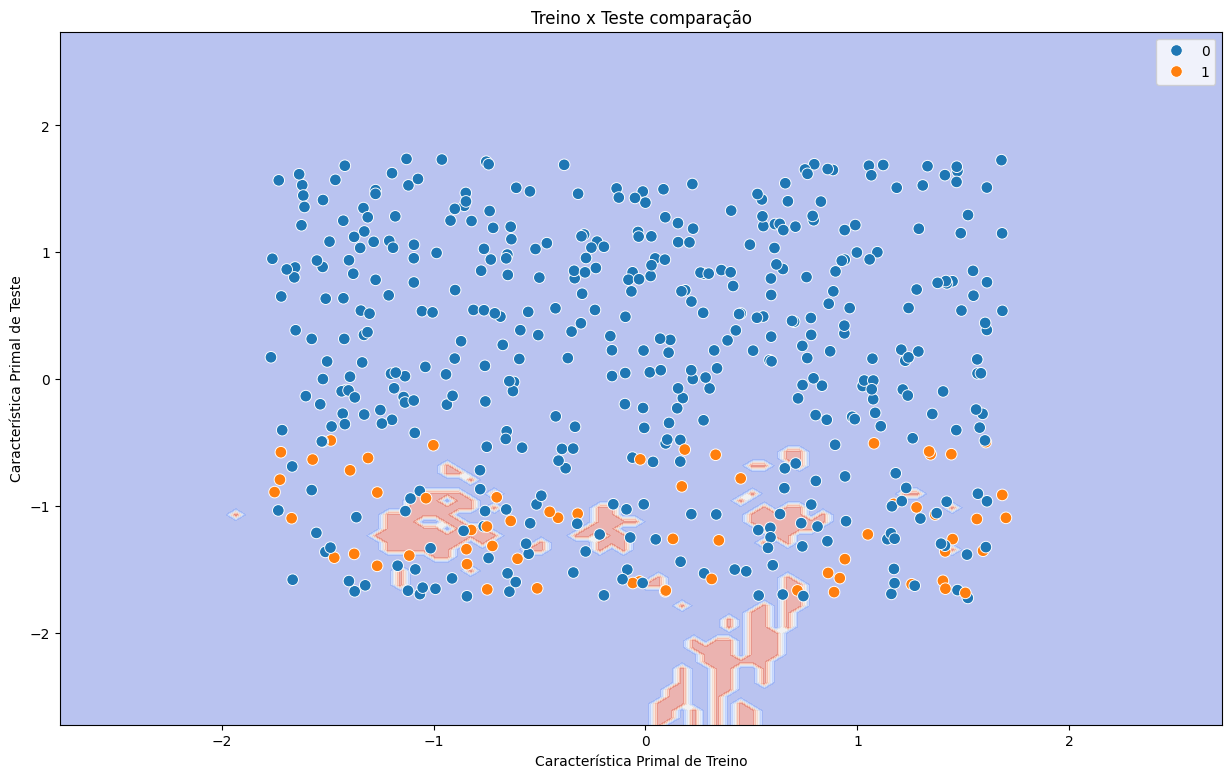

In [21]:
x_2d_t = X_credit_test[:, :2]
y_2d_t = y_credit_test

x_2d_r = X_credit_train[:, :2]
y_2d_r = y_credit_train

knn_2d = KNeighborsClassifier(n_neighbors=20, p=2)
knn_2d.fit(x_2d_r, y_2d_r)

fig, ax = plt.subplots(figsize=(15, 9))
DecisionBoundaryDisplay.from_estimator(
    knn_2d,
    x_2d_r,
    cmap="coolwarm",
    alpha=0.4,
    ax=ax,
    response_method="predict"
)
sn.scatterplot(
    x=x_2d_t[:, 0],
    y=x_2d_t[:, 1],
    hue=y_2d_t,
    s=70,
    ax=ax
)

plt.title("Treino x Teste comparação")
plt.xlabel("Característica Primal de Treino")
plt.ylabel("Característica Primal de Teste")